# Phase 2 — A mean-reversion signal on the KO / PEP spread, and its validation

**The brief asks** for a spread `KO − β × PEP` from an OLS regression, a check that it comes back to its
average, a z-score signal (long the spread when the z-score is very negative, short when very positive,
close near zero) and, above all, an **honest validation**: tune in-sample, test once out-of-sample, say
how many things were tried, check sensitivity to small changes.

**Result**
- The spread check is negative: with one β for 2000–2018 the spread drifts in multi-year waves
  (Engle-Granger p = 0.12, half-life ~9 months).
- In-sample (2001–2018) all 25 variants I tried earn a little, but none is significant: the chosen one
  has Sharpe 0.35, t = 1.49.
- Out-of-sample (2019–2026), run **once** with everything frozen: Sharpe **−0.53**. **The signal does
  not survive.** Cause: from 2024 KO and PEP drift apart and a static β cannot follow.

Supporting details are in the appendix at the end.

| Term | Meaning |
|---|---|
| Spread | `KO − β × PEP`: if the stocks are truly related it should hover around a stable average |
| Hedge ratio β | Dollars KO tends to move per dollar PEP moves, from the OLS line `KO = α + β × PEP` |
| z-score | How many standard deviations the spread is from its own rolling average (the last N days) today |
| Long / short the spread | Buy 1 KO and sell β PEP / the opposite |
| Sharpe ratio | Yearly return / yearly volatility: return per unit of risk (0.5 is decent, 1 is good) |
| t-statistic | Standard errors between the average daily return and zero; below about 2 it can be luck |
| Drawdown | Loss from the best value reached so far |
| In-sample / out-of-sample | 2000–2018, where I look and tune / 2019–2026, untouched until the strategy is frozen, then run once |
| Look-ahead | Using on a day information not yet known that day: it makes any backtest look better |

**The brief's Phase 2, sentence by sentence**

| The brief asks | What this notebook does | Section |
|---|---|---|
| "Run an OLS linear regression of one price on the other" and "Spread = PriceA − β · PriceB" | OLS of KO on PEP on in-sample adjusted prices; exactly this spread (α left out) | 1 |
| "You should actually check it" (plot; does it keep crossing its own average?) | Spread chart, crossings per year, half-life, Engle-Granger test | 1, A.1 |
| "Standardize the spread into a z-score" against "its own rolling average"; long when very negative, short when very positive, close back toward zero | z on a rolling window, past and today only; entry at ±threshold, exit at 0 | 2, A.2 |
| "Split your data into an in-sample and an out-of-sample period ... report both, separately" | 2000–2018 / 2019–2026, fixed before downloading any price; one table with both | top, 7 |
| "Be explicit about how many things you tried" | Every backtest in `results/trials.sqlite`: 50 | 6 |
| "Check how sensitive your result is to small changes (threshold, lookback window)" | 25-variant grid, the grid on two halves of the in-sample, 24 small changes | 3–5 |
| "Do not optimize on the out-of-sample period" | Rules committed before the first backtest; strategy committed before the single out-of-sample run | 2, 7 |

In [1]:
import pandas as pd
import plotly.graph_objects as go
import plotly.io as pio
from plotly.subplots import make_subplots
from statsmodels.tsa.stattools import coint

from pairs.backtest import run_zscore_strategy, select_stable_cell, summarize
from pairs.config import PAIR, PHASE2_STRATEGY, SIGNAL_GRID, Settings
from pairs.data import load_pair_prices
from pairs.logging_setup import configure_logging
from pairs.plots import equity_figure, finish_figure, save_figure
from pairs.spread import build_spread, fit_hedge_ratio, half_life, mean_crossings_per_year
from pairs.trials import count_trials, log_trial

configure_logging()
pio.renderers.default = "plotly_mimetype+png"
settings = Settings.from_env()
figures_dir = settings.results_dir / "figures"
trials_db = settings.results_dir / "trials.sqlite"
SOURCE_IS = "Source: Yahoo Finance adjusted close, in-sample period 3 Jan 2000 - 31 Dec 2018."
SOURCE_ALL = (
    "Source: Yahoo Finance adjusted close, 3 Jan 2000 - 9 Oct 2026."
    " Shaded: out-of-sample (run once)."
)
A, B, PAIR_NAME, S = (
    PAIR.ticker_a,
    PAIR.ticker_b,
    f"{PAIR.ticker_a}/{PAIR.ticker_b}",
    PHASE2_STRATEGY,
)

prices = load_pair_prices(PAIR, settings.data_dir, PAIR.in_sample_end)  # in-sample only: 2000-2018
all_prices = load_pair_prices(
    PAIR, settings.data_dir, PAIR.end
)  # used only for the out-of-sample run
fit = fit_hedge_ratio(prices, A, B, PAIR.in_sample_end)
start = prices.index[
    max(SIGNAL_GRID.windows) - 1
]  # first day with a full 250-day window: same for every variant
oos_start = all_prices.index[all_prices.index > pd.Timestamp(PAIR.in_sample_end)][0]
pd.Series(
    {
        "in-sample days": len(prices),
        "in-sample last day": prices.index[-1].date(),
        "backtests start": start.date(),
        "out-of-sample": f"{oos_start.date()} - {all_prices.index[-1].date()}",
    }
)

15:10:41 INFO     Loading raw checkpoint C:\Users\gianl\Documents\bsq-pairs-trading\data\prices_raw.pkl

         INFO     Removed wrong KO dividend of 2001-09-10 00:00:00 (factor 0.99276)

         INFO     Loaded 4779 days of KO/PEP up to 2018-12-31

         INFO     Loading raw checkpoint C:\Users\gianl\Documents\bsq-pairs-trading\data\prices_raw.pkl

         INFO     Removed wrong KO dividend of 2001-09-10 00:00:00 (factor 0.99276)

         INFO     Loaded 6733 days of KO/PEP up to 2026-10-09

         INFO     Kept 4779 of 4779 rows up to 2018-12-31

         INFO     Hedge fit KO on PEP up to 2018-12-31: HedgeFit(alpha=2.4082588482649627, beta=0.3883715977564579,
                  r_squared=0.926829730450619, as_of=datetime.date(2018, 12, 31), n_obs=4779)

in-sample days                           4779
in-sample last day                 2018-12-31
backtests start                    2000-12-27
out-of-sample         2019-01-02 - 2026-10-09
dtype: object

## Result at a glance

The frozen strategy (threshold 1.5, window 60 days, exit at 0, β = 0.388; how it was chosen is in
sections 2–5), first in-sample, then on the out-of-sample period it had never seen.

**About the order of this notebook.** It shows the result first for the reader, so it loads the
2019–2026 prices at the start. The real order of the work is not this notebook but the Git history:
rules committed before the first backtest, strategy frozen in a commit, and only then a single
out-of-sample run (section 7). Every estimate below (β, grid, choice) uses the in-sample prices only:
`load_pair_prices(..., PAIR.in_sample_end)` drops every later date and asserts it.

         INFO     Kept 4779 of 6733 rows up to 2018-12-31

         INFO     Hedge fit KO on PEP up to 2018-12-31: HedgeFit(alpha=2.4082588482649627, beta=0.3883715977564579,
                  r_squared=0.926829730450619, as_of=datetime.date(2018, 12, 31), n_obs=4779)

         INFO     Trial already logged, kept the first record: {'entry': 1.5, 'window': 60, 'exit': 0.0, 'beta':   
                  0.388372}

         INFO     Logged trial 50 (phase2-oos, out-of-sample, {'entry': 1.5, 'window': 60, 'exit': 0.0, 'beta':    
                  0.388372})

15:10:43 INFO     Saved figure C:\Users\gianl\Documents\bsq-pairs-trading\results\figures\02_equity_is_oos.png

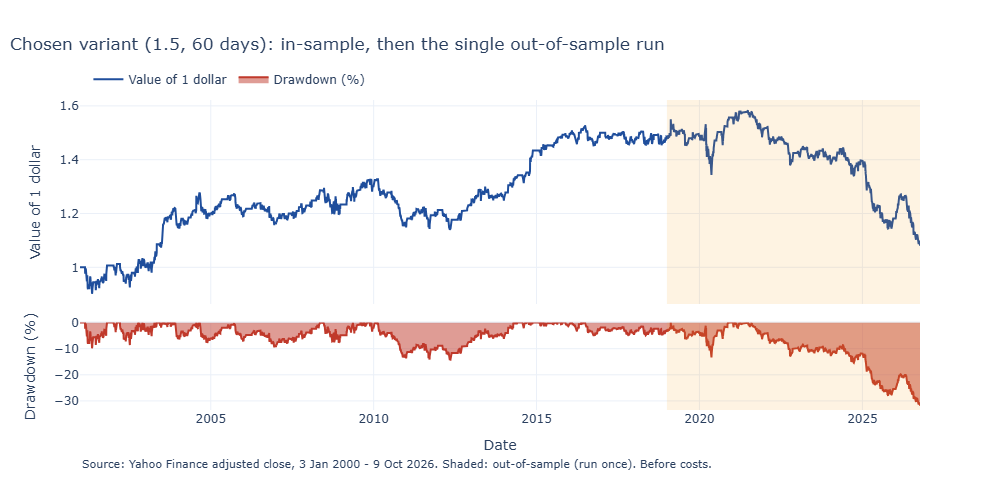

,in-sample 2001-2018,out-of-sample 2019-2026
ann_return,0.024,-0.038
ann_vol,0.069,0.072
sharpe,0.351,-0.534
t_stat,1.490,-1.486
max_drawdown,-0.144,-0.318
n_trades,94.000,36.000
pct_in_market,0.665,0.777
avg_days_per_trade,32.043,42.167


In [2]:
chosen_is = run_zscore_strategy(prices, A, B, fit.beta, S.entry, S.window, start).loc[start:]
is_stats = summarize(chosen_is["ret"], chosen_is["position"])
assert (
    abs(fit_hedge_ratio(all_prices, A, B, PAIR.in_sample_end).beta - S.beta) < 1e-6
)  # the frozen β
oos = run_zscore_strategy(all_prices, A, B, S.beta, S.entry, S.window, oos_start, S.exit).loc[
    oos_start:
]
oos_stats = summarize(oos["ret"], oos["position"])
log_trial(
    trials_db,
    "phase2-oos",
    PAIR_NAME,
    "out-of-sample",
    (oos_start.date(), oos.index[-1].date()),
    {"entry": S.entry, "window": S.window, "exit": S.exit, "beta": S.beta},
    oos_stats,
    "single out-of-sample run of the frozen strategy",
)
fig = equity_figure(
    pd.concat([chosen_is["ret"], oos["ret"]]),
    "Chosen variant (1.5, 60 days): in-sample, then the single out-of-sample run",
    SOURCE_ALL + " Before costs.",
    shade_from=oos_start,
)
save_figure(fig, "02_equity_is_oos", figures_dir)
fig.show()
pd.DataFrame({"in-sample 2001-2018": is_stats, "out-of-sample 2019-2026": oos_stats}).round(3)

## 1. The spread, and the brief's check

The two prices wander like random walks. If the stocks are truly related, some combination of them
should hover around a stable average. The plain difference KO − PEP does not work because they do not
move one-for-one, so I fit `KO = α + β × PEP` by OLS on **in-sample prices only** (the function drops
every date after 31 Dec 2018, and a test checks that changing a later price leaves β unchanged). β is
then frozen and reused unchanged out-of-sample.

**How to read the chart:** a spread that keeps crossing the dashed line (its 2000–2018 average) is
mean-reverting, which the strategy needs; one that stays on one side for years is drifting. The table
adds the brief's basic check (crossings per year), the **half-life** (days for a deviation to shrink by
half, from a regression of the daily change on the previous level) and the **Engle-Granger test**, the
standard test for a spread built from an estimated β (stricter than a plain Dickey-Fuller test, because
β was fitted to make the spread look as stable as possible; p < 0.05 would mean "mean-reverting").

15:10:47 INFO     Saved figure C:\Users\gianl\Documents\bsq-pairs-trading\results\figures\02_spread_is.png

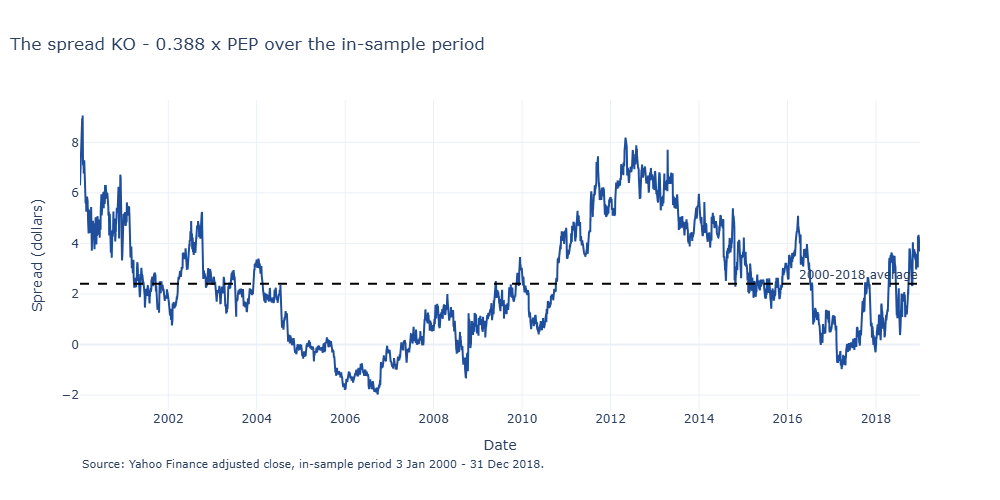

,in-sample
β (hedge ratio),0.3884
alpha (dollars),2.4080
R squared,0.9270
"crossings of the average, 2000-2018",116.0000
years with no crossing,8.0000
half-life (trading days),192.0000
Engle-Granger p-value,0.1170


In [3]:
spread = build_spread(prices, A, B, fit.beta)
fig = go.Figure()
fig.add_trace(
    go.Scatter(x=spread.index, y=spread, name="Spread KO - 0.388 x PEP", line={"color": "#1f4e9c"})
)
fig.add_hline(
    y=spread.mean(), line_dash="dash", line_color="black", annotation_text="2000-2018 average"
)
finish_figure(
    fig,
    "The spread KO - 0.388 x PEP over the in-sample period",
    "Date",
    "Spread (dollars)",
    SOURCE_IS,
)
save_figure(fig, "02_spread_is", figures_dir)
fig.show()
crossings = mean_crossings_per_year(spread)
spread_half_life = half_life(spread)
eg_stat, eg_pvalue, eg_critical = coint(prices[A], prices[B])
pd.Series(
    {
        "β (hedge ratio)": round(fit.beta, 4),
        "alpha (dollars)": round(fit.alpha, 3),
        "R squared": round(fit.r_squared, 3),
        "crossings of the average, 2000-2018": int(crossings.sum()),
        "years with no crossing": int((crossings == 0).sum()),
        "half-life (trading days)": round(spread_half_life, 1),
        "Engle-Granger p-value": round(eg_pvalue, 3),
    }
).to_frame("in-sample")

**Reading: the check is an honest *no*.** β = 0.388 (KO moves 39 cents per dollar of PEP). The high
R² only says both prices grew together. The spread crosses its average 116 times, but mostly in a few
years (23 in 2001, 38 in 2015); in 8 years out of 19 it never crosses. It moves in **waves of several
years**: below average from 2004 to 2009, above from 2011 to 2014. A deviation takes about 192 trading
days (9 months) to halve and the Engle-Granger test does not reject a drift (p = 0.12). With a single β
for 19 years the long-run relationship is weak.

I still go on, because the brief's z-score uses the spread's **rolling** average, which follows the slow
waves: the signal bets on short swings around the recent level. Whether that works is what the
validation has to show.

## 2. The signal and the rules, fixed before the first backtest

**Signal**, with prices known at each close: z = (spread − mean of the last N days) / std of the last N
days. Flat → long the spread if z < −threshold, short if z > +threshold; close when z comes back to 0.
The position decided at the close of day t earns the move of day t+1 (no look-ahead; tested). Daily
return = P&L of both legs / dollars invested the day before (value of KO plus value of PEP, both
counted positive), 0 on days without a position; adjusted prices include dividends, so the short leg
pays them. **No
costs**: the brief puts them in the extensions, so every number is *before costs*.

**Rules**, written in `src/pairs/config.py` (`SIGNAL_GRID`) and committed (`feat: pre-register phase 2
signal grid and selection rule`) **before any backtest**, having seen only the in-sample spread:

| Rule | Value | Why |
|---|---|---|
| Entry thresholds | 1.0, 1.5, 2.0, 2.5, 3.0 | The middle three are the brief's own example ("1.5, 2, 2.5"). 1.0 and 3.0 are edges, there only to see what happens just outside (1.0 is not really "very negative": it trades almost every swing) |
| Windows (days) | 20, 60, 120, 190, 250 | The brief leaves the window free. With a half-life of ~192 days, windows much shorter bet on short swings around the recent average, windows close to it on the spread's own pace; the grid covers both ideas. 20 = a month, 60 and 120 = a quarter and a half-year (the range the brief uses in Phase 3), 190 ≈ the half-life, 250 = a trading year |
| Exit | z = 0 | The brief: "close the position when it reverts back toward zero". Not tuned: one thing less tried |
| β | 0.388, in-sample OLS, frozen | The in-sample is "where you look and tune": β is estimated there and never re-estimated on later data |
| Same period for all variants | from 27 Dec 2000 | The first day the 250-day window is full; shorter windows would otherwise get an extra year |
| Selection | best **zone**, not best cell | Below |

**Selection rule.** The best of 25 cells is the luckiest one. So for each of the 9 interior cells
(thresholds 1.5/2/2.5 × windows 60/120/190) I average the Sharpe ratio of the cell and its 8 neighbours
and take the highest: the centre of the zone that works even if the parameters are a bit off. **Edge
cells cannot be chosen**: they have only 5 or 3 neighbours, so their average is noisier and the
comparison would not be fair; they still count as neighbours. A cell needs at least 20 in-sample trades
(a Sharpe ratio over a handful of trades is chance); ties go to fewer trades. Whatever the outcome, even
if every cell lost, the chosen cell goes out-of-sample and the result is reported as it is. Written down
in advance: with 19 years of data, an in-sample Sharpe below about 0.4 is compatible with pure luck
after 25 attempts.
**Sensitivity**: after the choice, 24 small changes around it (threshold ±0.1/±0.2, window ±5%/±10%),
diagnostic only.

## 3. The 25 in-sample variants

Same days for all (27 Dec 2000 – 31 Dec 2018), each logged once in `results/trials.sqlite`.
**How to read it:** each square is one variant (row = threshold, column = window); blue = positive
Sharpe ratio, red = negative. A wide blue area means the result does not hinge on one lucky
combination; an isolated blue square in a red sea would be a warning.

15:10:50 INFO     Trial already logged, kept the first record: {'entry': 1.0, 'window': 20, 'exit': 0.0, 'beta':   
                  0.388372}

         INFO     Logged trial 1 (phase2-grid, in-sample, {'entry': 1.0, 'window': 20, 'exit': 0.0, 'beta':        
                  0.388372})

         INFO     Trial already logged, kept the first record: {'entry': 1.0, 'window': 60, 'exit': 0.0, 'beta':   
                  0.388372}

         INFO     Logged trial 2 (phase2-grid, in-sample, {'entry': 1.0, 'window': 60, 'exit': 0.0, 'beta':        
                  0.388372})

         INFO     Trial already logged, kept the first record: {'entry': 1.0, 'window': 120, 'exit': 0.0, 'beta':  
                  0.388372}

...

         INFO     Trial already logged, kept the first record: {'entry': 3.0, 'window': 190, 'exit': 0.0, 'beta':  
                  0.388372}

         INFO     Logged trial 24 (phase2-grid, in-sample, {'entry': 3.0, 'window': 190, 'exit': 0.0, 'beta':      
                  0.388372})

         INFO     Trial already logged, kept the first record: {'entry': 3.0, 'window': 250, 'exit': 0.0, 'beta':  
                  0.388372}

         INFO     Logged trial 25 (phase2-grid, in-sample, {'entry': 3.0, 'window': 250, 'exit': 0.0, 'beta':      
                  0.388372})

15:10:52 INFO     Saved figure C:\Users\gianl\Documents\bsq-pairs-trading\results\figures\02_grid_sharpe.png

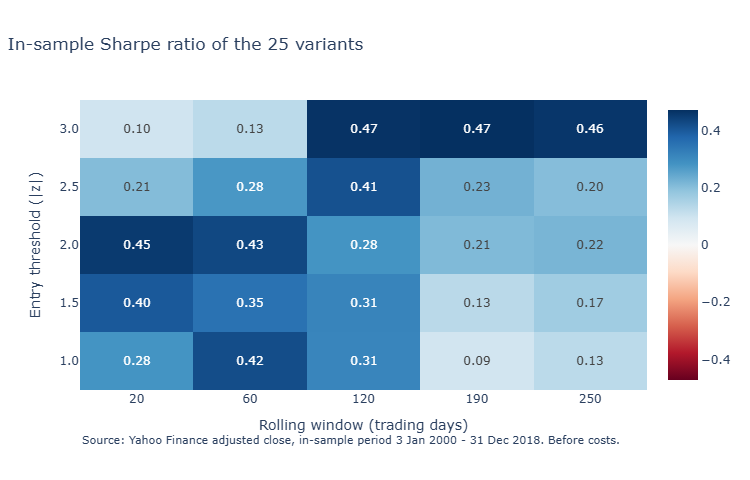

15:10:54 INFO     Stable zone centre: entry 1.5, window 60 (score 0.361)

window,60,120,190
zone score: entry,,,
1.5,0.361,0.282,0.206
2.0,0.347,0.292,0.240
2.5,0.306,0.322,0.328


In [4]:
HALVES = {
    "2001-2009": (start, pd.Timestamp("2009-12-31")),
    "2010-2018": (pd.Timestamp("2010-01-01"), prices.index[-1]),
}


def run_variant(entry: float, window: int, phase: str, note: str = "") -> dict[str, float]:
    out = run_zscore_strategy(prices, A, B, fit.beta, entry, window, start).loc[start:]
    stats = summarize(out["ret"], out["position"])
    for name, (first, last) in HALVES.items():
        part = out.loc[first:last]
        stats[f"sharpe {name}"] = summarize(part["ret"], part["position"])["sharpe"]
    params = {"entry": entry, "window": window, "exit": 0.0, "beta": round(fit.beta, 6)}
    log_trial(
        trials_db,
        phase,
        PAIR_NAME,
        "in-sample",
        (start.date(), PAIR.in_sample_end),
        params,
        stats,
        note,
    )
    return {"entry": entry, "window": window, **stats}


def heatmap(
    table: pd.DataFrame,
    title: str,
    name: str,
    fmt: str = ".2f",
    colorscale: str = "RdBu",
    zmid: float | None = 0.0,
) -> go.Figure:
    fig = go.Figure(
        go.Heatmap(
            z=table.to_numpy(),
            x=[str(c) for c in table.columns],
            y=[str(i) for i in table.index],
            colorscale=colorscale,
            zmid=zmid,
            texttemplate="%{z:" + fmt + "}",
            colorbar={"title": ""},
        )
    )
    finish_figure(
        fig,
        title,
        "Rolling window (trading days)",
        "Entry threshold (|z|)",
        SOURCE_IS + " Before costs.",
    )
    fig.update_layout(width=750, height=480)
    save_figure(fig, name, figures_dir)
    return fig


grid = pd.DataFrame(
    [
        run_variant(e, w, "phase2-grid")
        for e in SIGNAL_GRID.entry_thresholds
        for w in SIGNAL_GRID.windows
    ]
)
sharpe = grid.pivot(index="entry", columns="window", values="sharpe")
trades = grid.pivot(index="entry", columns="window", values="n_trades")
heatmap(sharpe, "In-sample Sharpe ratio of the 25 variants", "02_grid_sharpe").show()
values = sharpe.to_numpy()
zone = pd.DataFrame(
    [[values[i - 1 : i + 2, j - 1 : j + 2].mean() for j in range(1, 4)] for i in range(1, 4)],
    index=sharpe.index[1:4],
    columns=sharpe.columns[1:4],
)
chosen = select_stable_cell(sharpe, trades, SIGNAL_GRID.min_trades)
assert chosen == (S.entry, S.window)  # the frozen strategy is the rule's output
zone.round(3).rename_axis(index="zone score: entry", columns="window")

**Reading.** All 25 variants earn before costs (Sharpe 0.09 to 0.47): no lonely lucky cell. But the
amounts are small (0.3–3% a year) and **no variant reaches t = 2**. The rule picks **1.5 / 60 days**
(zone score 0.361); its own Sharpe ratio, 0.35, is not the grid's best (0.47 sits on an edge with only
17 trades), which is the point of the rule. It makes 94 trades in 18 years (about 32 days each, in a
position 66% of the days); one dollar becomes about 1.48 (+2.4% a year), worst drawdown 14%: a t of
1.49, below the luck threshold written in advance. Two reasons to read even this as optimistic: β was estimated on
the same years, and there are no costs.

## 4. Is the good zone stable over time?

The same 25 backtests, scored on the two halves of the in-sample period. If the blue zone stays in
place the parameters are stable; if it moves, the "best" parameters are an average of two regimes.

15:10:56 INFO     Saved figure C:\Users\gianl\Documents\bsq-pairs-trading\results\figures\02_grid_halves.png

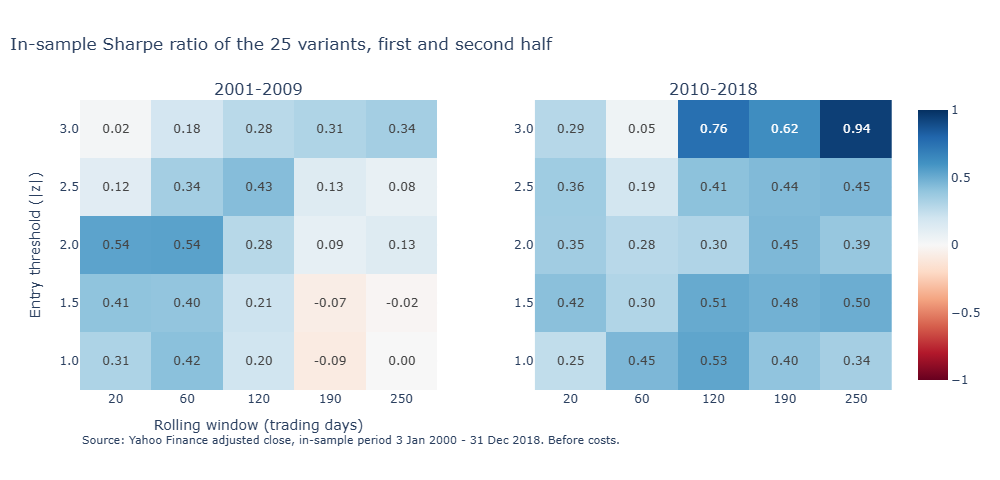

In [5]:
fig = make_subplots(rows=1, cols=2, subplot_titles=list(HALVES), horizontal_spacing=0.12)
for col, name in enumerate(HALVES, start=1):
    table = grid.pivot(index="entry", columns="window", values=f"sharpe {name}")
    fig.add_trace(
        go.Heatmap(
            z=table.to_numpy(),
            x=[str(c) for c in table.columns],
            y=[str(i) for i in table.index],
            colorscale="RdBu",
            zmid=0,
            zmin=-1,
            zmax=1,
            texttemplate="%{z:.2f}",
            showscale=col == 2,
        ),
        row=1,
        col=col,
    )
finish_figure(
    fig,
    "In-sample Sharpe ratio of the 25 variants, first and second half",
    "Rolling window (trading days)",
    "Entry threshold (|z|)",
    SOURCE_IS + " Before costs.",
)
fig.update_layout(width=1000, height=480)
save_figure(fig, "02_grid_halves", figures_dir)
fig.show()

**Reading: the good zone moves.** In 2001–2009 short windows work best and long ones lose; in
2010–2018 it is the opposite. The chosen variant holds in both halves (0.40 and 0.30), but the "right"
parameter is not stable across decades: a warning for the out-of-sample test.

## 5. Small changes of the parameters

The brief: "If a tiny change collapses the result, that is a sign you found noise." 24 small changes
around the chosen cell (centre), logged as trials, never used to choose again.

15:10:59 INFO     Trial already logged, kept the first record: {'entry': 1.3, 'window': 54, 'exit': 0.0, 'beta':   
                  0.388372}

         INFO     Logged trial 26 (phase2-zoom, in-sample, {'entry': 1.3, 'window': 54, 'exit': 0.0, 'beta':       
                  0.388372})

         INFO     Trial already logged, kept the first record: {'entry': 1.3, 'window': 57, 'exit': 0.0, 'beta':   
                  0.388372}

         INFO     Logged trial 27 (phase2-zoom, in-sample, {'entry': 1.3, 'window': 57, 'exit': 0.0, 'beta':       
                  0.388372})

         INFO     Trial already logged, kept the first record: {'entry': 1.3, 'window': 60, 'exit': 0.0, 'beta':   
                  0.388372}

...

         INFO     Trial already logged, kept the first record: {'entry': 1.7, 'window': 63, 'exit': 0.0, 'beta':   
                  0.388372}

         INFO     Logged trial 48 (phase2-zoom, in-sample, {'entry': 1.7, 'window': 63, 'exit': 0.0, 'beta':       
                  0.388372})

         INFO     Trial already logged, kept the first record: {'entry': 1.7, 'window': 66, 'exit': 0.0, 'beta':   
                  0.388372}

         INFO     Logged trial 49 (phase2-zoom, in-sample, {'entry': 1.7, 'window': 66, 'exit': 0.0, 'beta':       
                  0.388372})

15:11:01 INFO     Saved figure C:\Users\gianl\Documents\bsq-pairs-trading\results\figures\02_zoom_sharpe.png

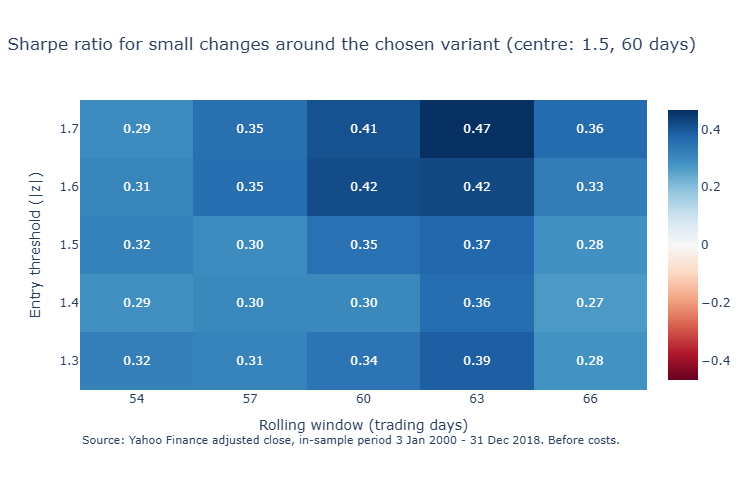

In [6]:
zoom = pd.DataFrame(
    [
        run_variant(
            round(chosen[0] + off, 2),
            round(chosen[1] * fac),
            "phase2-zoom",
            f"zoom around {chosen}",
        )
        if (round(chosen[0] + off, 2), round(chosen[1] * fac)) != chosen
        else grid.set_index(["entry", "window"]).loc[chosen].to_dict()
        | {"entry": chosen[0], "window": chosen[1]}
        for off in SIGNAL_GRID.threshold_offsets
        for fac in SIGNAL_GRID.window_factors
    ]
)
heatmap(
    zoom.pivot(index="entry", columns="window", values="sharpe"),
    "Sharpe ratio for small changes around the chosen variant (centre: 1.5, 60 days)",
    "02_zoom_sharpe",
).show()

**Reading.** No collapse: Sharpe between 0.27 and 0.47 for every small change. Robust, but not
strong: the t-statistics stay between 1.1 and 2.0.

## 6. How many things I tried

In [7]:
pd.Series(
    {
        "grid (to choose)": count_trials(trials_db, "phase2-grid"),
        "zoom (small changes)": count_trials(trials_db, "phase2-zoom"),
        "out-of-sample runs": count_trials(trials_db, "phase2-oos"),
    }
).to_frame("Phase 2 backtests logged")

,Phase 2 backtests logged
grid (to choose),25
zoom (small changes),24
out-of-sample runs,1


**50 backtests**: 49 in-sample (25 to choose with one rule written in advance, 24 to check small
changes) and 1 out-of-sample. Nothing else: no other exit, stop-loss, β window or regression direction.
I did not tune further because section 4 shows the best parameters change from one decade to the next:
more tuning would only describe the past better.

## 7. Out-of-sample: the single run, and why it fails

**Order of events, visible in the Git history:** (1) the chosen variant was frozen in `config.py` as
`PHASE2_STRATEGY` and committed (`feat: freeze the phase 2 strategy before the out-of-sample run`);
(2) the 49 in-sample trials were committed (`chore: log the 49 in-sample phase 2 trials`); (3) only
then were the 2019–2026 prices used, once (`chore: log the single phase 2 out-of-sample run`). The strategy starts flat on 2 Jan 2019, so no in-sample trade spills
over; the z-score of early January uses the last 60 days of 2018, which is the past and allowed.
Pre-registered reading: it
survives if its out-of-sample Sharpe ratio is positive. The run is in the chart at the top; this
notebook re-executes it with the same frozen values, so the trial log does not count it twice.

**Verdict: it does not survive.** Sharpe −0.53, −3.8% a year, worst drawdown 32%, mostly in 2025
(−15%) and 2026 (−9%). With t = −1.49 it is not a proven loser either: 7.8 years cannot separate a small
effect from zero. What is shown is that there is **no evidence it makes money**. Before blaming the
market I looked for a mistake: no missing prices, the largest moves are the real ones of March 2020,
trades per year match the in-sample, β re-estimated equals the frozen one.

15:11:05 INFO     Saved figure C:\Users\gianl\Documents\bsq-pairs-trading\results\figures\02_spread_full.png

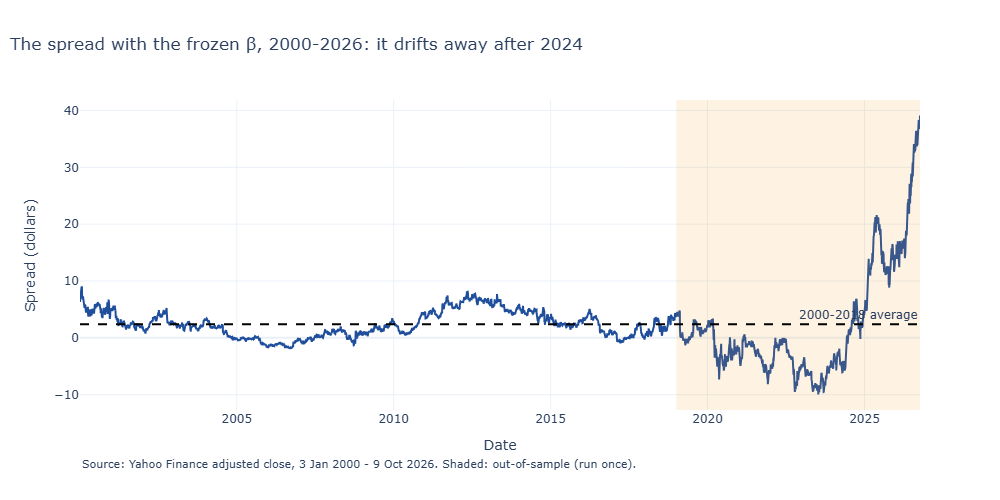

,out-of-sample
return 2025,-15.4%
return 2026,-8.6%
P&L of long trades ($ per KO share),-10.36
P&L of short trades ($ per KO share),-26.12
"KO/PEP price ratio, 2023 average",0.345
"KO/PEP price ratio, 2026 average",0.558


In [8]:
yearly = oos["ret"].groupby(oos.index.year).apply(lambda r: (1 + r).prod() - 1)
full_spread = build_spread(all_prices, A, B, S.beta)
fig = go.Figure()
fig.add_vrect(
    x0=oos_start, x1=full_spread.index[-1], fillcolor="#f39c12", opacity=0.12, line_width=0
)
fig.add_trace(
    go.Scatter(
        x=full_spread.index,
        y=full_spread,
        name="Spread KO - 0.388 x PEP",
        line={"color": "#1f4e9c"},
    )
)
fig.add_hline(
    y=spread.mean(), line_dash="dash", line_color="black", annotation_text="2000-2018 average"
)
finish_figure(
    fig,
    "The spread with the frozen β, 2000-2026: it drifts away after 2024",
    "Date",
    "Spread (dollars)",
    SOURCE_ALL,
)
save_figure(fig, "02_spread_full", figures_dir)
fig.show()
held = oos["position"].shift(1).fillna(0)
ratio = all_prices[A] / all_prices[B]
pd.Series(
    {
        "return 2025": f"{yearly[2025]:.1%}",
        "return 2026": f"{yearly[2026]:.1%}",
        "P&L of long trades ($ per KO share)": round(oos.loc[held > 0, "pnl"].sum(), 2),
        "P&L of short trades ($ per KO share)": round(oos.loc[held < 0, "pnl"].sum(), 2),
        "KO/PEP price ratio, 2023 average": round(ratio.loc["2023"].mean(), 3),
        "KO/PEP price ratio, 2026 average": round(ratio.loc["2026"].mean(), 3),
    }
).to_frame("out-of-sample")

**Why it fails.** From 2024 Coca-Cola grows much faster than PepsiCo: the price ratio goes from 0.35
to 0.56 and the spread climbs from about −7 to +24 dollars, far above anything seen in 2000–2018. The
strategy keeps shorting the spread, betting the climb will reverse, and the rolling average catches up
at a loss: most of the loss comes from the **short** trades. This is the drift the brief describes in
Phase 3, and it matches Phase 1: the KO/PEP ratio has moved in waves lasting decades.

## 8. What I learn, and what I am unsure about

**What I learn**
- The brief's spread check fails for KO/PEP with a static β: multi-year waves, half-life ~9 months,
  Engle-Granger p = 0.12.
- In-sample the z-score signal earns a little in every variant and is robust to small changes, but weak
  (Sharpe 0.35, t = 1.49) and its best parameters move between decades.
- **50 backtests, rules fixed in advance, one out-of-sample run: the signal did not survive.** My
  read: the in-sample gains mostly described that period's swings, and a static β cannot follow a
  relationship that drifts for years.

**What I am unsure about**
- In-sample numbers are optimistic: β uses the same years, and there are no costs.
- 7.8 out-of-sample years are few: even a true Sharpe ratio of 0.5 could look like zero there.
- One pair and one split: Phase 5 (simulated paths) and the walk-forward extension test whether the
  conclusion depends on this slice of history.
- β estimated on price levels gives more weight to the later, higher prices.
- **A hypothesis, not a result:** a β that moves with the relationship (rolling, Phase 3; Kalman,
  extension) might have kept the spread closer to a stable average. It could also fail: an adaptive β
  absorbs part of the divergences the strategy wants to trade. It must be tested with its own rules
  and its own out-of-sample run, without touching the strategy frozen here.

## Appendix: supporting details

**A.1 Crossings of the in-sample average, year by year** (the brief's basic check).

15:11:09 INFO     Saved figure C:\Users\gianl\Documents\bsq-pairs-trading\results\figures\02_mean_crossings.png

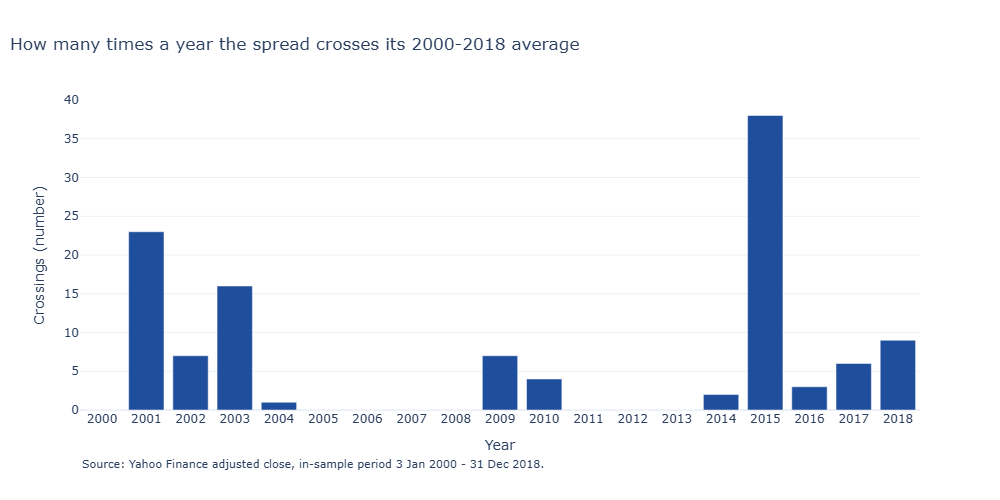

In [9]:
fig = go.Figure(go.Bar(x=crossings.index, y=crossings, marker_color="#1f4e9c", name="crossings"))
finish_figure(
    fig,
    "How many times a year the spread crosses its 2000-2018 average",
    "Year",
    "Crossings (number)",
    SOURCE_IS,
)
fig.update_xaxes(dtick=1)
save_figure(fig, "02_mean_crossings", figures_dir)
fig.show()

**A.2 The signal at work, 2002–2003.** The line is z; a trade opens when it crosses ±1.5 (triangles)
and closes when it comes back to 0 (crosses).

15:11:14 INFO     Saved figure C:\Users\gianl\Documents\bsq-pairs-trading\results\figures\02_signal_example.png

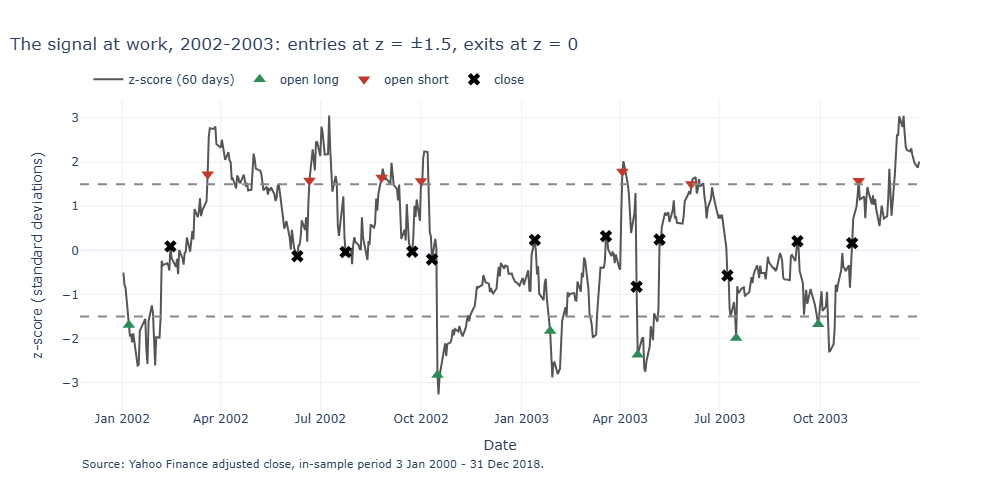

In [10]:
example = run_zscore_strategy(prices, A, B, fit.beta, S.entry, S.window, start).loc["2002":"2003"]
pos, prev = example["position"], example["position"].shift(1).fillna(0)
fig = go.Figure()
fig.add_trace(
    go.Scatter(x=example.index, y=example["z"], name="z-score (60 days)", line={"color": "#555555"})
)
for level in (-S.entry, S.entry):
    fig.add_hline(y=level, line_dash="dash", line_color="#888888")
for label, mask, symbol, color in [
    ("open long", (pos == 1) & (prev != 1), "triangle-up", "#2e8b57"),
    ("open short", (pos == -1) & (prev != -1), "triangle-down", "#c0392b"),
    ("close", (pos == 0) & (prev != 0), "x", "black"),
]:
    fig.add_trace(
        go.Scatter(
            x=example.index[mask],
            y=example["z"][mask],
            mode="markers",
            name=label,
            marker={"symbol": symbol, "size": 11, "color": color},
        )
    )
finish_figure(
    fig,
    "The signal at work, 2002-2003: entries at z = ±1.5, exits at z = 0",
    "Date",
    "z-score (standard deviations)",
    SOURCE_IS,
)
save_figure(fig, "02_signal_example", figures_dir)
fig.show()

**A.3 Number of trades and full metrics of the 25 variants.** Short windows trade a lot (303 trades
with 1.0 / 20 days), long windows with high thresholds very little (12 with 3.0 / 250: too few to trust).

15:11:18 INFO     Saved figure C:\Users\gianl\Documents\bsq-pairs-trading\results\figures\02_grid_trades.png

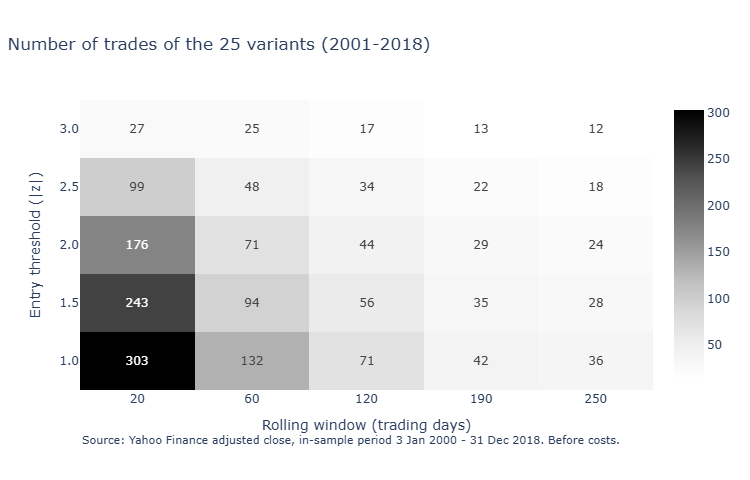

sharpe  t_stat  ann_return  max_drawdown  n_trades  \
entry window                                                       
1.0   20        0.28    1.19        0.02         -0.16     303.0   
      60        0.42    1.79        0.03         -0.13     132.0   
      120       0.31    1.32        0.02         -0.14      71.0   
      190       0.09    0.39        0.01         -0.20      42.0   
      250       0.13    0.54        0.01         -0.19      36.0   
1.5   20        0.40    1.70        0.03         -0.13     243.0   
      60        0.35    1.49        0.02         -0.14      94.0   
      120       0.31    1.33        0.02         -0.14      56.0   
      190       0.13    0.54        0.01         -0.20      35.0   
      250       0.17    0.71        0.01         -0.17      28.0   
2.0   20        0.45    1.92        0.03         -0.11     176.0   
      60        0.43    1.82        0.03         -0.13      71.0   
      120       0.28    1.19        0.02         -0.13      44.0   
      190       0.21    0.89        0.01         -0.18      29.0   
      250       0.22    0.93        0.01         -0.16      24.0   
2.5   20        0.21    0.87        0.01         -0.14      99.0   
      60        0.28    1.17        0.01         -0.14      48.0   
      120       0.41    1.75        0.02         -0.12      34.0   
      190       0.23    0.96        0.01         -0.13      22.0   
      250       0.20    0.86        0.01         -0.14      18.0   
3.0   20        0.10    0.41        0.00         -0.12      27.0   
      60        0.13    0.54        0.00         -0.11      25.0   
      120       0.47    1.98        0.02         -0.10      17.0   
      190       0.47    2.00        0.02         -0.06      13.0   
      250       0.46    1.95        0.02         -0.12      12.0   

              pct_in_market  avg_days_per_trade  
entry window                                     
1.0   20               0.78               11.62  
      60               0.77               26.55  
      120              0.77               49.15  
      190              0.78               84.10  
      250              0.80              100.94  
1.5   20               0.67               12.49  
      60               0.66               32.04  
      120              0.68               55.05  
      190              0.73               94.17  
      250              0.74              119.61  
2.0   20               0.51               13.16  
      60               0.53               33.70  
      120              0.60               61.36  
      190              0.67              105.28  
      250              0.67              126.08  
2.5   20               0.34               15.58  
      60               0.41               38.52  
      120              0.47               62.82  
      190              0.54              110.95  
      250              0.57              144.39  
3.0   20               0.10               17.26  
      60               0.26               46.72  
      120              0.23               61.53  
      190              0.27               94.46  
      250              0.28              105.75

In [11]:
heatmap(
    trades,
    "Number of trades of the 25 variants (2001-2018)",
    "02_grid_trades",
    fmt=".0f",
    colorscale="Greys",
    zmid=None,
).show()
grid.set_index(["entry", "window"])[
    [
        "sharpe",
        "t_stat",
        "ann_return",
        "max_drawdown",
        "n_trades",
        "pct_in_market",
        "avg_days_per_trade",
    ]
].round(2)

**A.4 The chosen variant on the in-sample period alone.**

15:11:23 INFO     Saved figure C:\Users\gianl\Documents\bsq-pairs-trading\results\figures\02_equity_is.png

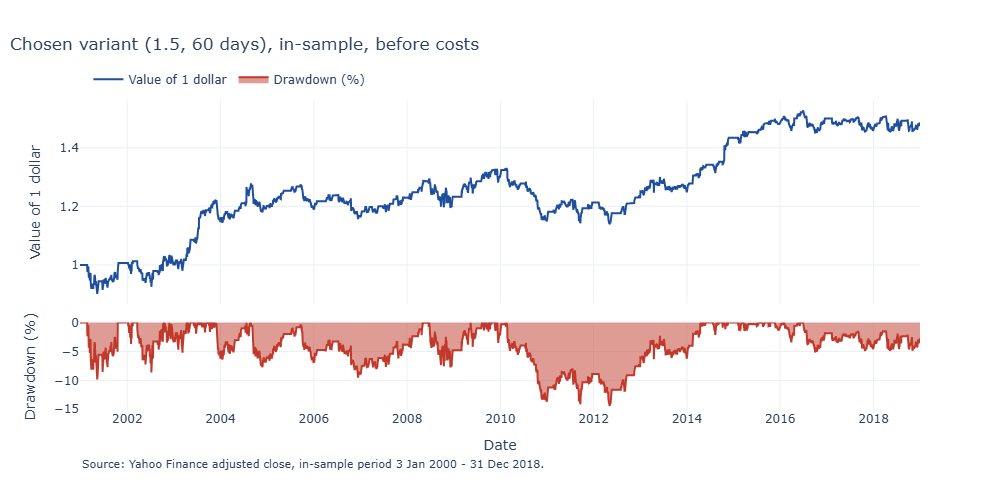

In [12]:
fig = equity_figure(
    chosen_is["ret"], "Chosen variant (1.5, 60 days), in-sample, before costs", SOURCE_IS
)
save_figure(fig, "02_equity_is", figures_dir)
fig.show()

In [13]:
# Every number quoted in the text, checked (expected values recorded on 10 Oct 2026)
assert len(prices) == 4779 and prices.index[-1] == pd.Timestamp("2018-12-31")
assert (
    abs(fit.beta - 0.388372) < 1e-6
    and abs(fit.alpha - 2.408) < 1e-3
    and abs(fit.r_squared - 0.927) < 1e-3
)
assert (
    int(crossings.sum()) == 116
    and crossings[2001] == 23
    and crossings[2015] == 38
    and (crossings == 0).sum() == 8
)
assert abs(spread_half_life - 192.0) < 0.5 and abs(eg_pvalue - 0.117) < 0.005
assert start == pd.Timestamp("2000-12-27")
assert len(grid) == 25 and (grid["sharpe"] > 0).all()
assert abs(grid["sharpe"].min() - 0.09) < 0.005 and abs(grid["sharpe"].max() - 0.47) < 0.006
assert (grid["t_stat"] < 2).all()
assert chosen == (1.5, 60) and abs(zone.loc[1.5, 60] - 0.361) < 0.001
g = grid.set_index(["entry", "window"])
assert (
    abs(is_stats["sharpe"] - 0.35) < 0.005
    and abs(is_stats["t_stat"] - 1.49) < 0.005
    and is_stats["n_trades"] == 94
)
assert abs(is_stats["max_drawdown"] + 0.14) < 0.005 and abs(is_stats["ann_return"] - 0.024) < 0.001
assert abs((1 + chosen_is["ret"]).prod() - 1.48) < 0.005
assert (
    abs(grid["ann_return"].min() - 0.003) < 0.0005
    and abs(grid["ann_return"].max() - 0.031) < 0.0005
)
assert (
    g.loc[(1.0, 20), "n_trades"] == 303
    and g.loc[(3.0, 250), "n_trades"] == 12
    and g.loc[(3.0, 120), "n_trades"] == 17
)
assert (
    abs(g.loc[chosen, "sharpe 2001-2009"] - 0.40) < 0.005
    and abs(g.loc[chosen, "sharpe 2010-2018"] - 0.30) < 0.005
)
assert (
    len(zoom) == 25
    and abs(zoom["sharpe"].min() - 0.27) < 0.005
    and abs(zoom["sharpe"].max() - 0.47) < 0.005
)
assert zoom["t_stat"].min() > 1.05 and zoom["t_stat"].max() < 2.0
assert count_trials(trials_db, "phase2-grid") == 25 and count_trials(trials_db, "phase2-zoom") == 24
assert count_trials(trials_db, "phase2-oos") == 1
assert oos_start == pd.Timestamp("2019-01-02") and oos.index[-1] == pd.Timestamp("2026-10-09")
assert abs(oos_stats["sharpe"] + 0.53) < 0.005 and abs(oos_stats["ann_return"] + 0.038) < 0.001
assert abs(oos_stats["t_stat"] + 1.49) < 0.005 and abs(oos_stats["max_drawdown"] + 0.32) < 0.005
assert oos_stats["n_trades"] == 36
assert abs(yearly[2025] + 0.154) < 0.001 and abs(yearly[2026] + 0.086) < 0.001
assert oos.loc[held < 0, "pnl"].sum() < oos.loc[held > 0, "pnl"].sum() < 0
assert abs(ratio.loc["2023"].mean() - 0.35) < 0.01 and abs(ratio.loc["2026"].mean() - 0.56) < 0.01
for name in (
    "02_spread_is",
    "02_mean_crossings",
    "02_signal_example",
    "02_grid_sharpe",
    "02_grid_trades",
    "02_grid_halves",
    "02_zoom_sharpe",
    "02_equity_is",
    "02_equity_is_oos",
    "02_spread_full",
):
    assert (figures_dir / f"{name}.png").exists(), name